# Global Daily SST (OSTIA) Analysis: Identifying Marine Extremes with `MarEx-Detect`

This notebook turns 40 years (1982-2022) of daily OSTIA sea-surface temperature, regridded to 0.25° (720 × 1440 cells),
into a boolean record of marine heatwaves with two combinations of anomaly and threshold method:

| | Anomaly | Threshold |
|---|---|---|
| Section 1 | `shifting_baseline`: anomaly from a smoothed day-of-year climatology of the preceding `window_years` (15) | `seasonal_percentile`: day-of-year 95th percentile, after Hobday et al. (2016) |
| Section 2 | `detrend_harmonic`: removes the mean, the annual & semi-annual harmonics, and a linear + quadratic trend | `global_percentile`: one 95th percentile per cell over all days |

Section 3 compares the two. The shifting baseline consumes its first `window_years` as spin-up, so its record starts
15 years after the input does. That record feeds the tracking example, `02_id_track_events.ipynb`. The other two
anomaly methods (`fixed_baseline` and `detrend_fixed_baseline`) and the trade-offs between all four are described under
[Choosing an Anomaly Method](https://marex.readthedocs.io/en/latest/guide/anomalies.html#choosing-a-method).

Compute: detection runs on a dask cluster of 256 single-threaded workers (7.8 GB each), started as 8 SLURM jobs of
32 workers on the compute partition. The notebook kernel itself needs only a modest session. The table at the end
reports wall time and memory per stage.

## Setup

In [1]:
import calendar
from getpass import getuser
from pathlib import Path

import dask
import dask.array as da
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

import marEx
import marEx.helper as hpc

2026-10-18 22:27:03 - marEx - INFO - [PID:2273093] - MarEx logging configured - Level: INFO, Mode: normal


In [2]:
scratch_dir = Path("/scratch") / getuser()[0] / getuser()  # Lustre scratch
sst_store = (
    scratch_dir / "marEx_data" / "input" / "ostia" / "ostia.zarr"
)  # daily OSTIA SST on a 0.25° grid, 1982-01-01 to 2022-05-31
out_dir = scratch_dir / "marEx" / "examples" / "gridded"

period = slice("1982-01-01", "2022-05-31")  # 40 years of input
window_years = 15  # shifting-baseline length in years. Part 1's output starts this many years after `period`
plot_window = slice("2016-01-01", "2021-12-31")  # x-range of the time-series figures

# Workers run as short SLURM jobs on the compute partition: single-threaded, 32 per 256 GB node (7.8 GB each), 256 in all
n_workers, workers_per_node, runtime = 256, 32, 119  # workers, per 256 GB node, minutes per worker job

In [3]:
out_dir.mkdir(parents=True, exist_ok=True)

# graphs of a few hundred MB are expected at this scale
dask.config.set({"distributed.admin.large-graph-warning-threshold": "1GB"})

# Each group of 32 workers is its own SLURM job on the compute partition. The walls cover the whole run: dask's P2P
# rechunk does not survive a worker leaving mid-shuffle, so workers are neither retired early nor replaced.
client = hpc.start_distributed_cluster(
    n_workers=n_workers,
    workers_per_node=workers_per_node,
    runtime=runtime,
    node_memory=256,
    scratch_dir=scratch_dir / "marEx" / "dask",
)
client.wait_for_workers(n_workers, timeout=1800)

# Records wall time, peak memory, spill and worker restarts for each `monitor.stage(...)` block below
monitor = hpc.ResourceMonitor(client)

2026-10-18 22:27:06 - marEx.helper.cluster - INFO - [PID:2273093] - Starting distributed SLURM cluster - 256 workers on 8 nodes


2026-10-18 22:27:06 - marEx.helper.cluster - INFO - [PID:2273093] - Configuration: 32 workers/node, 256GB memory/node, 119 min runtime


2026-10-18 22:27:06 - marEx.helper.dask_config - INFO - [PID:2273093] - Configuring Dask for HPC environment


2026-10-18 22:27:06 - marEx.helper.dask_config - INFO - [PID:2273093] - Dask temporary directory: /scratch/b/b382615/marEx/dask/tmpy_fv4bj_


2026-10-18 22:27:06 - marEx.helper.dask_config - INFO - [PID:2273093] - Dask configuration completed


...

2026-10-18 22:27:08 - marEx.helper.cluster - INFO - [PID:2273093] - Completed SLURM cluster creation in 1.14s


2026-10-18 22:27:08 - marEx.helper.cluster - INFO - [PID:2273093] - Memory limit per worker: 7.81 GB


2026-10-18 22:27:08 - marEx.helper.cluster - INFO - [PID:2273093] - Scaling cluster to 256 workers


Hostname: l40012
Forward Port: l40012:8889
Dashboard Link: localhost:8889/status
2026-10-18 22:27:08 - marEx.helper.cluster - INFO - [PID:2273093] - Distributed cluster started successfully


2026-10-18 22:31:23 - marEx.helper.resources - INFO - [PID:2273093] - Cluster: 256 workers, 256 threads, memory_limit per worker [7.8] GB (2001 GB total)


## 1. Shifting Baseline & Hobday Threshold

Both methods read the input with one chunking: a small time chunk and the whole domain in each chunk
(`{"time": 30, "lat": -1, "lon": -1}`). The climatology and percentile reductions are global in time, so a task's
memory is `n_time × (cells in one spatial chunk) × 4 B`, and marEx tiles the spatial dimension internally wherever a
reduction needs it. A large time chunk would only inflate each input chunk to several GB. The sizing rules are under
[Memory Management and Chunking](https://marex.readthedocs.io/en/latest/guide/performance.html#chunking).

In [4]:
sst = xr.open_zarr(sst_store, chunks={"time": 30, "lat": -1, "lon": -1}).sst.sel(time=period)
sst

<xarray.DataArray 'sst' (time: 14761, lat: 720, lon: 1440)> Size: 61GB
dask.array<open_dataset-sst, shape=(14761, 720, 1440), dtype=float32, chunksize=(30, 720, 1440), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float32 3kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float32 6kB -179.9 -179.6 -179.4 -179.1 ... 179.4 179.6 179.9
  * time     (time) datetime64[ns] 118kB 1982-01-01T12:00:00 ... 2022-05-31T1...
Attributes:
    comment:         OSTIA foundation SST
    long_name:      analysed sea surface temperature
    reference:      C.J. Donlon, M. Martin,J.D. Stark, J. Roberts-Jones, E. F...
    source:         AMSR2-REMSS-L2P-v2.0, AMSRE-REMSS-L2P-v2.0, TMI-REMSS-L2P...
    standard_name:  sea_surface_foundation_temperature
    units:          kelvin
    valid_max:      4500
    valid_min:      -300

In [5]:
with monitor.stage("Detect: shifting baseline + Hobday"):
    extremes_ds = marEx.preprocess_data(
        sst,
        method_anomaly="shifting_baseline",  # anomaly from a backward-looking climatology of the previous `window_years`
        method_extreme="seasonal_percentile",  # day-of-year threshold (Hobday et al., 2016)
        threshold_percentile=95,
        window_years=window_years,
        smooth_days=21,  # smoothing applied to the climatology (days)
        window_days=11,  # samples from an 11-day window around each day of year enter its percentile
        dimensions={"time": "time", "x": "lon", "y": "lat"},  # a "y" dimension tells marEx this is a lat/lon grid
        dask_chunks={"time": 25},  # chunking of the output
    )
    extremes_ds.to_zarr(out_dir / "extremes_shifting_hobday.zarr", mode="w")
extremes_ds

2026-10-18 22:31:55 - marEx.pipeline - INFO - [PID:2273093] - Starting data preprocessing - Method: shifting_baseline -> seasonal_percentile


2026-10-18 22:31:55 - marEx.pipeline - INFO - [PID:2273093] - Parameters: percentile=95%, method_percentile=approximate


2026-10-18 22:31:55 - marEx.anomaly.api - INFO - [PID:2273093] - Computing anomalies - method: shifting_baseline


2026-10-18 22:32:06 - marEx.anomaly.api - INFO - [PID:2273093] - Starting Anomaly computation using shifting_baseline method


2026-10-18 22:32:08 - marEx.anomaly.api - INFO - [PID:2273093] - Completed Anomaly computation using shifting_baseline method in 1.81s


...

2026-10-18 22:35:08 - marEx.core.finalise - INFO - [PID:2273093] - Starting Dataset persistence and optimisation


2026-10-18 22:35:08 - marEx.core.finalise - INFO - [PID:2273093] - Completed Dataset persistence and optimisation in 0.03s


2026-10-18 22:35:22 - marEx.extremes.api - INFO - [PID:2273093] - Extreme identification completed - <xarray.DataArray 'extreme_events' ()> Size: 8B
array(286116865) extreme events identified


Detect: shifting baseline + Hobday: 3.5 min, peak worker memory 1110.8 GB of 2001 GB (largest worker 5.3 of 7.8 GB), client 2.2 GB, spilled 46.6 GB, restarts 0


<xarray.Dataset> Size: 50GB
Dimensions:         (lat: 720, lon: 1440, time: 9282, dayofyear: 366)
Coordinates:
  * lat             (lat) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * lon             (lon) float32 6kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
  * time            (time) datetime64[ns] 74kB 1997-01-01T12:00:00 ... 2022-0...
  * dayofyear       (dayofyear) uint16 732B 1 2 3 4 5 6 ... 362 363 364 365 366
Data variables:
    dat_anomaly     (time, lat, lon) float32 38GB dask.array<chunksize=(25, 720, 1440), meta=np.ndarray>
    mask            (lat, lon) bool 1MB dask.array<chunksize=(720, 1440), meta=np.ndarray>
    extreme_events  (time, lat, lon) bool 10GB dask.array<chunksize=(25, 720, 1440), meta=np.ndarray>
    thresholds      (lat, lon, dayofyear) float32 2GB dask.array<chunksize=(720, 1440, 25), meta=np.ndarray>
Attributes: (12/13)
    method_anomaly:        shifting_baseline
    preprocessing_steps:   ['Rolling climatology using 15 years', 'Smoothed w...
    window_years:          15
    smooth_days:           21
    smooth_max_missing:    0.1
    method_extreme:        seasonal_percentile
    ...                    ...
    tail:                  upper
    window_days:           11
    window_spatial:        5
    method_percentile:     approximate
    precision:             0.014025858561197917
    max_anomaly:           21.038787841796875

## 2. Harmonic Detrend & Global Threshold

Same input, so the `sst` opened above is reused.

In [6]:
with monitor.stage("Detect: harmonic detrend + global threshold"):
    extremes_ds = marEx.preprocess_data(
        sst,
        method_anomaly="detrend_harmonic",  # removes the mean, annual & semi-annual harmonics and the trend
        method_extreme="global_percentile",  # one threshold per cell, over all days
        threshold_percentile=95,
        detrend_orders=[1, 2],  # linear + quadratic trend
        dimensions={"time": "time", "x": "lon", "y": "lat"},
        dask_chunks={"time": 25},
    )
    extremes_ds.to_zarr(out_dir / "extremes_harmonic_global.zarr", mode="w")
extremes_ds

2026-10-18 22:35:26 - marEx.pipeline - INFO - [PID:2273093] - Starting data preprocessing - Method: detrend_harmonic -> global_percentile


2026-10-18 22:35:26 - marEx.pipeline - INFO - [PID:2273093] - Parameters: percentile=95%, method_percentile=approximate


2026-10-18 22:35:26 - marEx.anomaly.api - INFO - [PID:2273093] - Computing anomalies - method: detrend_harmonic


2026-10-18 22:35:28 - marEx.anomaly.api - INFO - [PID:2273093] - Starting Anomaly computation using detrend_harmonic method


2026-10-18 22:35:29 - marEx.anomaly.api - INFO - [PID:2273093] - Completed Anomaly computation using detrend_harmonic method in 1.11s


...

2026-10-18 22:36:07 - marEx.core.finalise - INFO - [PID:2273093] - Starting Dataset persistence and optimisation


2026-10-18 22:36:07 - marEx.core.finalise - INFO - [PID:2273093] - Completed Dataset persistence and optimisation in 0.03s


2026-10-18 22:36:11 - marEx.extremes.api - INFO - [PID:2273093] - Extreme identification completed - <xarray.DataArray 'extreme_events' ()> Size: 8B
array(482984267) extreme events identified


Detect: harmonic detrend + global threshold: 0.8 min, peak worker memory 440.2 GB of 2001 GB (largest worker 2.8 of 7.8 GB), client 2.4 GB, spilled 0.0 GB, restarts 0


<xarray.Dataset> Size: 77GB
Dimensions:         (lat: 720, lon: 1440, time: 14761)
Coordinates:
  * lat             (lat) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * lon             (lon) float32 6kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
  * time            (time) datetime64[ns] 118kB 1982-01-01T12:00:00 ... 2022-...
Data variables:
    dat_anomaly     (time, lat, lon) float32 61GB dask.array<chunksize=(25, 720, 1440), meta=np.ndarray>
    mask            (lat, lon) bool 1MB dask.array<chunksize=(720, 1440), meta=np.ndarray>
    extreme_events  (time, lat, lon) bool 15GB dask.array<chunksize=(25, 720, 1440), meta=np.ndarray>
    thresholds      (lat, lon) float64 8MB dask.array<chunksize=(720, 1440), meta=np.ndarray>
Attributes:
    method_anomaly:        detrend_harmonic
    preprocessing_steps:   ['Removed polynomial trend orders=[1, 2] & seasona...
    detrend_orders:        [1, 2]
    force_zero_mean:       1
    standardise:           0
    method_extreme:        global_percentile
    threshold_percentile:  95
    tail:                  upper
    method_percentile:     approximate
    precision:             0.012176350911458333
    max_anomaly:           18.2645263671875

## 3. Comparing the Two Methods

Both outputs are compared over the shifting-baseline record, which starts `window_years` after the input.

In [7]:
extremes_ds_shifting = xr.open_zarr(out_dir / "extremes_shifting_hobday.zarr", chunks={})
time_slice = slice(extremes_ds_shifting.time.values[0], extremes_ds_shifting.time.values[-1])
compare_chunks = {"time": 75, "lat": "auto", "lon": "auto"}

sst = xr.open_zarr(sst_store, chunks={}).sst.sel(time=time_slice).chunk(compare_chunks)
extremes_ds_shifting = extremes_ds_shifting.sel(time=time_slice).chunk(compare_chunks)
extremes_ds_detrend = xr.open_zarr(out_dir / "extremes_harmonic_global.zarr", chunks={}).sel(time=time_slice).chunk(compare_chunks)

methods = {"Shifting+Hobday": extremes_ds_shifting, "Harmonic+Global": extremes_ds_detrend}

### Time Series, Thresholds and Anomalies

A single threshold for every day of the year (`Harmonic+Global`) flags spurious extremes whenever the seasonal cycle
shifts systematically, for example when the seasonal transition arrives a little earlier or later than usual. The
day-of-year threshold (`Shifting+Hobday`) follows the season.

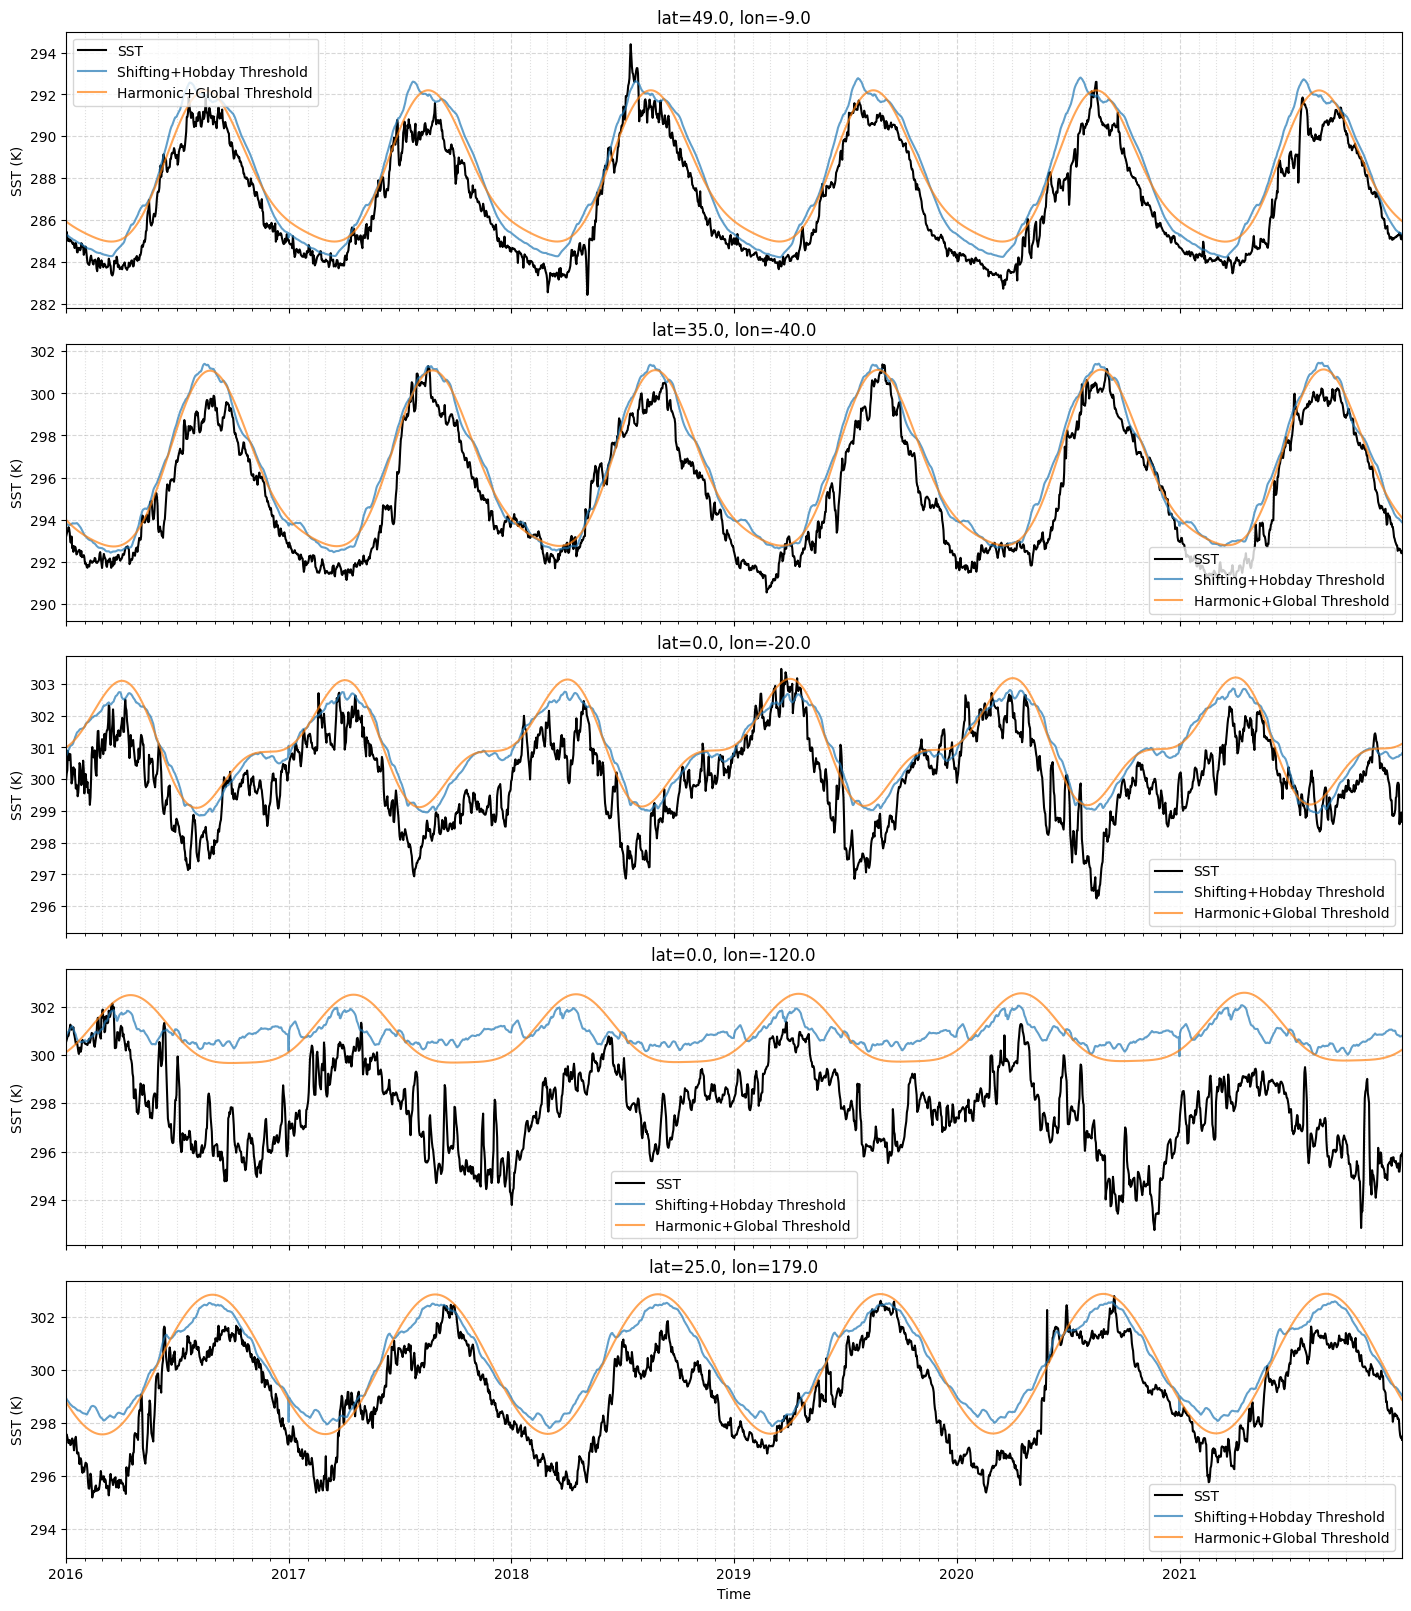

In [8]:
points = [
    (49.0, 351.0 - 360.0),
    (35.0, 320.0 - 360.0),
    (0.0, 340.0 - 360.0),
    (0.0, 240.0 - 360.0),
    (25.0, 179.0),
]


def plot_points(curves, ylabel):
    """One panel per point in `points`. `curves` maps a legend label to (field, plot keyword arguments)."""
    _, axes = plt.subplots(len(points), 1, figsize=(14, 16), sharex=True, layout="constrained")
    for ax, (lat_pt, lon_pt) in zip(axes, points):
        for label, (field, kwargs) in curves.items():
            field_pt = field.sel(lat=lat_pt, lon=lon_pt, method="nearest")
            ax.plot(field_pt.time, field_pt, label=label, **kwargs)
        ax.set_xlim(np.datetime64(plot_window.start), np.datetime64(plot_window.stop))
        ax.set_ylabel(ylabel)
        ax.grid(True, which="major", linestyle="--", alpha=0.5)
        ax.grid(True, which="minor", linestyle=":", alpha=0.4, axis="x")
        ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(2, 13)))
        ax.set_title(f"lat={lat_pt}, lon={lon_pt}")
        ax.legend()
    axes[-1].set_xlabel("Time")
    plt.show()


# Thresholds in SST units: SST - anomaly is the baseline, to which each method's threshold is added
shifting_threshold = sst - extremes_ds_shifting.dat_anomaly + extremes_ds_shifting.thresholds.sel(dayofyear=sst.time.dt.dayofyear)
detrend_threshold = sst - extremes_ds_detrend.dat_anomaly + extremes_ds_detrend.thresholds

plot_points(
    {
        "SST": (sst, {"color": "black"}),
        "Shifting+Hobday Threshold": (shifting_threshold, {"color": "tab:blue", "alpha": 0.7}),
        "Harmonic+Global Threshold": (detrend_threshold, {"color": "tab:orange", "alpha": 0.7}),
    },
    "SST (K)",
)

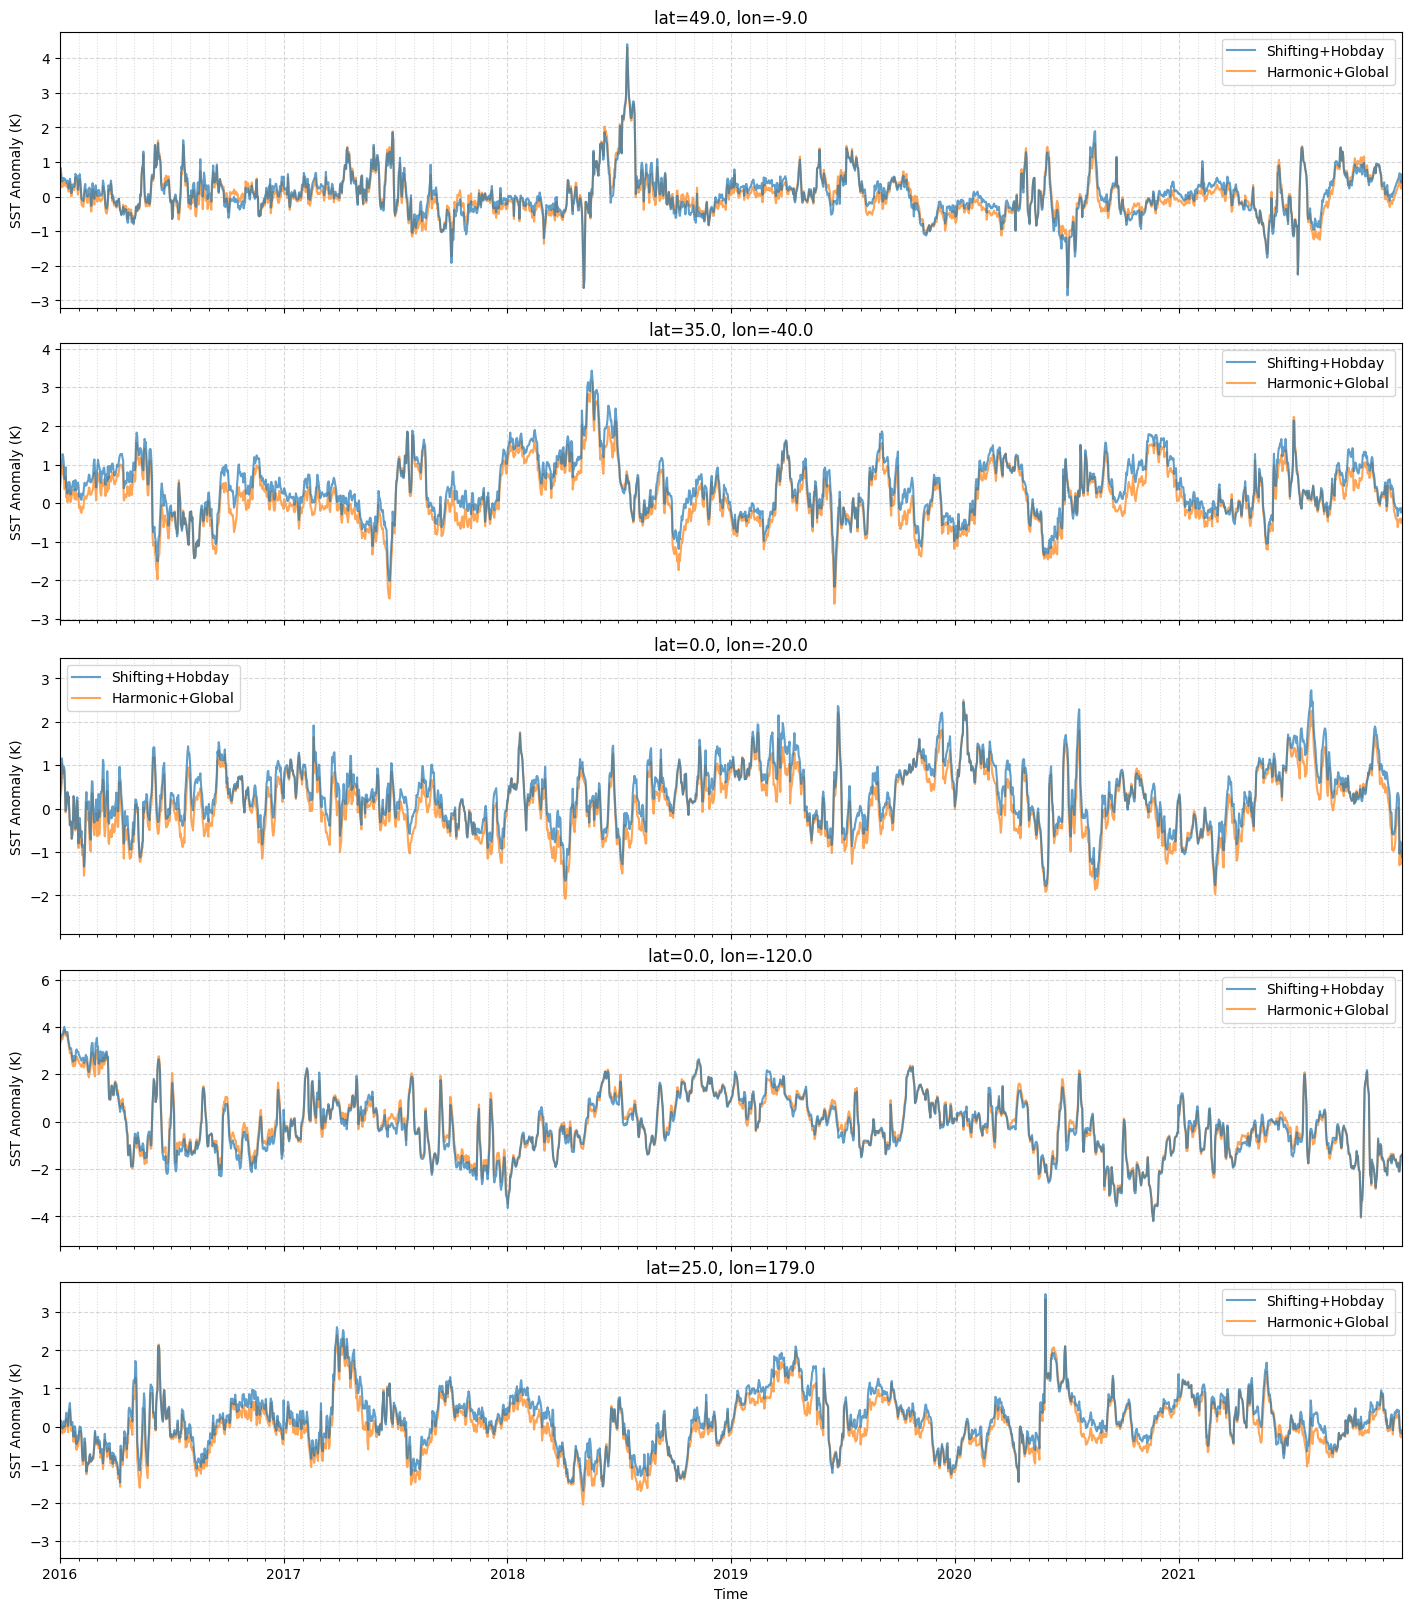

In [9]:
plot_points(
    {
        "Shifting+Hobday": (extremes_ds_shifting.dat_anomaly, {"color": "tab:blue", "alpha": 0.7, "zorder": 2}),
        "Harmonic+Global": (extremes_ds_detrend.dat_anomaly, {"color": "tab:orange", "alpha": 0.7, "zorder": 1}),
    },
    "SST Anomaly (K)",
)

### Anomaly Distributions and Variance

The positive shift of the shifting-baseline anomalies comes from the backward-looking climatology. It is intended: the
baseline is the recent past that an adapting organism has experienced.

The harmonic fit (the mean plus annual & semi-annual harmonics) cannot represent the shape of the seasonal cycle
everywhere. Its anomalies keep some residual seasonal structure, which shows in the seasonal variance maps below, although the
total variability of the two methods is similar. With one threshold per cell (`global_percentile`), that residual
structure becomes a seasonal bias in how often extremes are flagged.

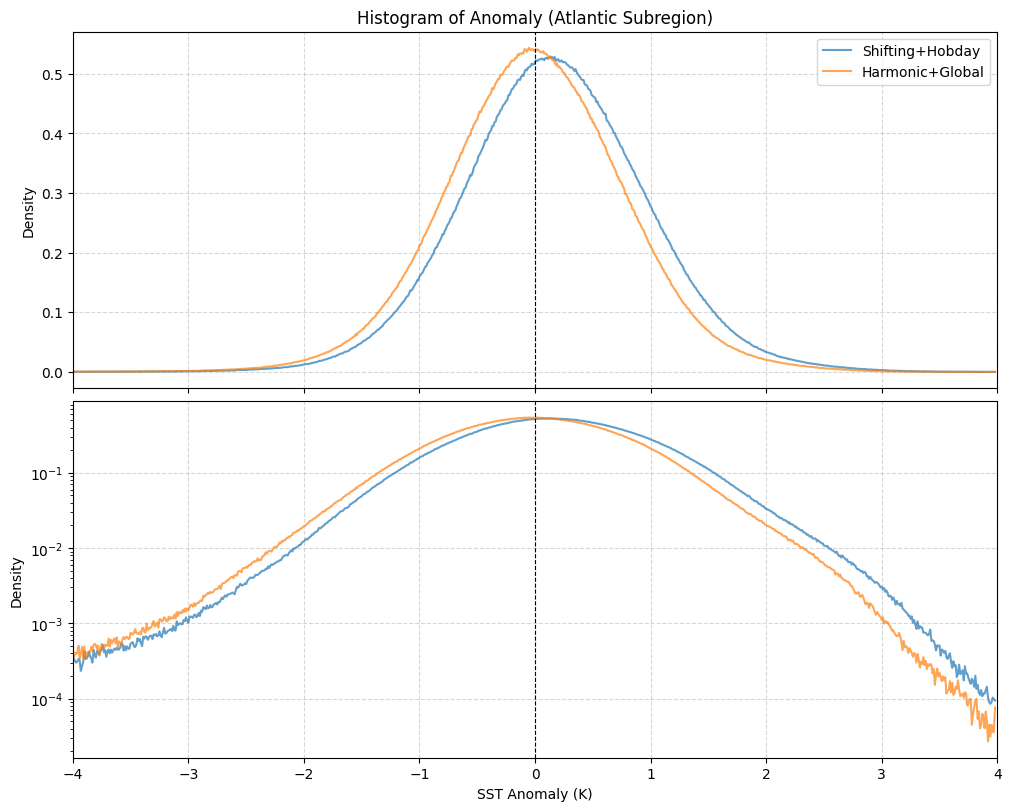

In [10]:
bins = np.arange(-4, 4, 0.01)
atlantic = {"lat": slice(35, 40), "lon": slice(-50, -20)}

hists = dask.compute(*[da.histogram(ds.dat_anomaly.sel(**atlantic).data, bins=bins, density=True)[0] for ds in methods.values()])

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, layout="constrained")
for ax, yscale in zip(axes, ["linear", "log"]):
    for name, hist in zip(methods, hists):
        ax.plot(bins[:-1], hist, label=name, alpha=0.7)
    ax.set_yscale(yscale)
    ax.set_ylabel("Density")
    ax.set_xlim(-4, 4)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
axes[0].set_title("Histogram of Anomaly (Atlantic Subregion)")
axes[0].legend()
axes[1].set_xlabel("SST Anomaly (K)")
plt.show()

2026-10-18 22:37:37 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:37:51 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 13.80s


2026-10-18 22:37:51 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:38:05 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 13.75s


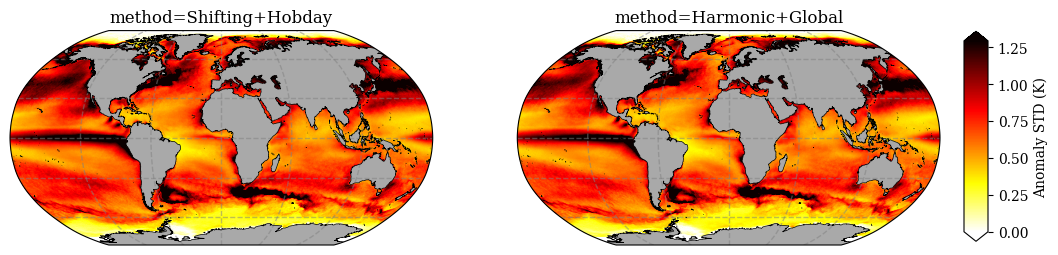

In [11]:
def by_method(stat):
    """Apply `stat` to each method's dataset and stack the results along a `method` dimension."""
    return xr.concat([stat(ds) for ds in methods.values()], dim="method").assign_coords(method=list(methods))


def plot_by_season(field, config):
    """One figure per season, the two methods side by side."""
    for season in field.season.values:
        fig, _ = field.sel(season=season).plotX.multi_plot(config, col="method", col_wrap=2)
        fig.suptitle(f"Season: {season}", fontsize=14)
        plt.show()


std_config = marEx.PlotConfig(var_units="Anomaly STD (K)", cmap="hot_r", cperc=[0, 96], grid_labels=True)
fig, axes = by_method(lambda ds: ds.dat_anomaly.std(dim="time")).plotX.multi_plot(std_config, col="method", col_wrap=2)

2026-10-18 22:38:44 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:38:50 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 5.64s


2026-10-18 22:38:50 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:38:56 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 5.62s


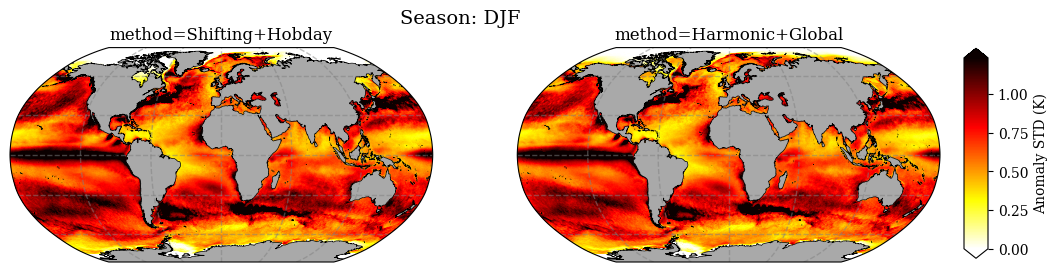

2026-10-18 22:38:59 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:39:04 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 5.42s


2026-10-18 22:39:04 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:39:10 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 5.34s


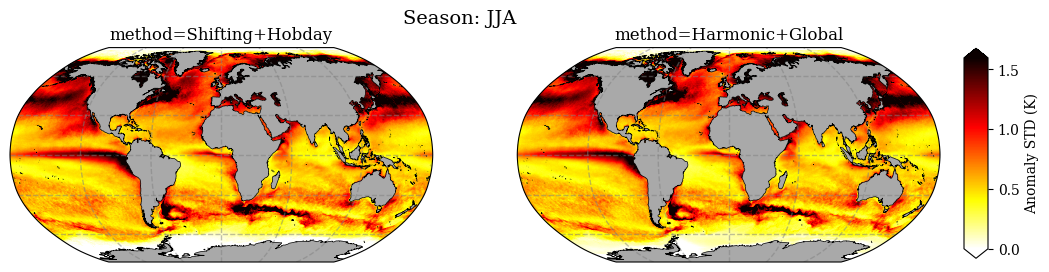

2026-10-18 22:39:13 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:39:18 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 5.37s


2026-10-18 22:39:18 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:39:24 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 5.39s


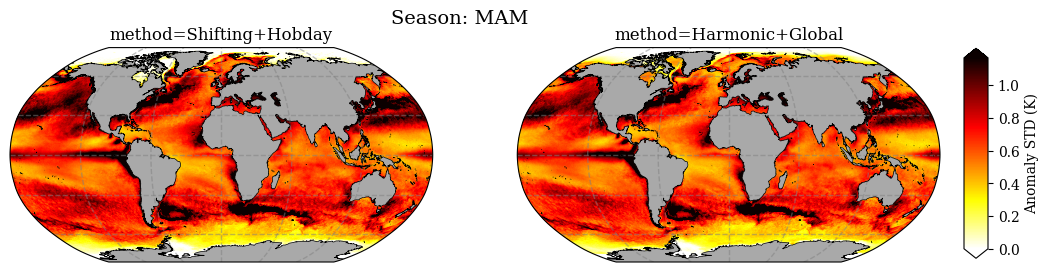

2026-10-18 22:39:27 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:39:32 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 5.38s


2026-10-18 22:39:32 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:39:37 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 5.30s


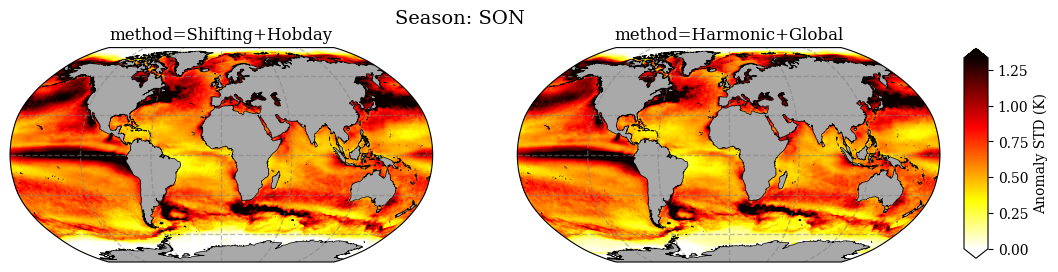

In [12]:
seasonal_std = by_method(lambda ds: ds.dat_anomaly.groupby("time.season").std(dim="time")).persist()

config = marEx.PlotConfig(
    var_units="Anomaly STD (K)",
    cmap="hot_r",
    cperc=[0, 96],
    grid_labels=False,
    show_colorbar=True,
)
plot_by_season(seasonal_std, config)

### Extreme Event Frequency

Under the Hobday definition, extremes are by construction relative to the time of year. The seasonal pattern in the
harmonic-detrended frequency comes largely from the part of the seasonal cycle that the harmonics miss (cf. the time
series above).

2026-10-18 22:39:43 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:39:51 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 7.64s


2026-10-18 22:39:51 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:40:02 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 11.60s


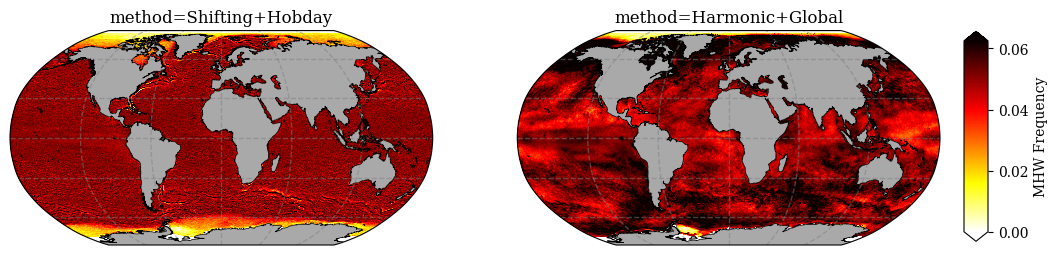

In [13]:
frequency_config = marEx.PlotConfig(var_units="MHW Frequency", cmap="hot_r", cperc=[0, 96], grid_labels=True)
fig, axes = by_method(lambda ds: ds.extreme_events.mean(dim="time")).plotX.multi_plot(frequency_config, col="method", col_wrap=2)

2026-10-18 22:40:07 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:40:20 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 12.71s


2026-10-18 22:40:20 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:40:26 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 6.12s


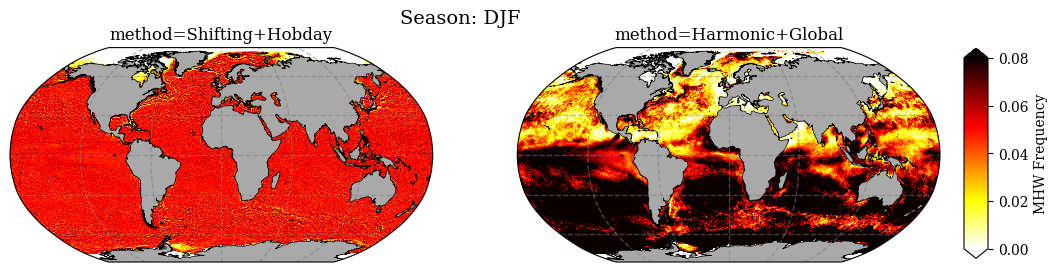

2026-10-18 22:40:29 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:40:35 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 6.08s


2026-10-18 22:40:35 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:40:41 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 6.06s


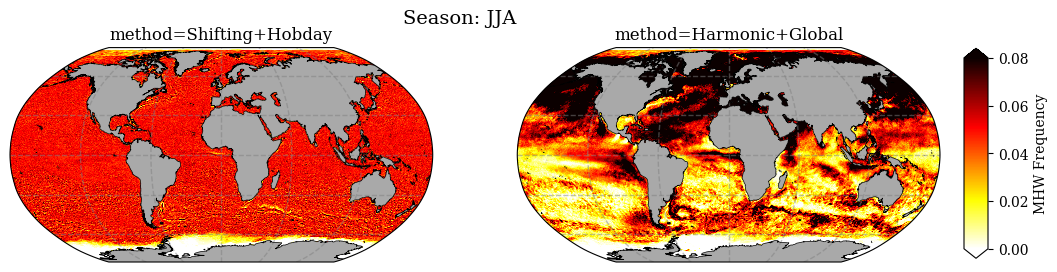

2026-10-18 22:40:45 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:40:51 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 6.05s


2026-10-18 22:40:51 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:40:57 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 6.10s


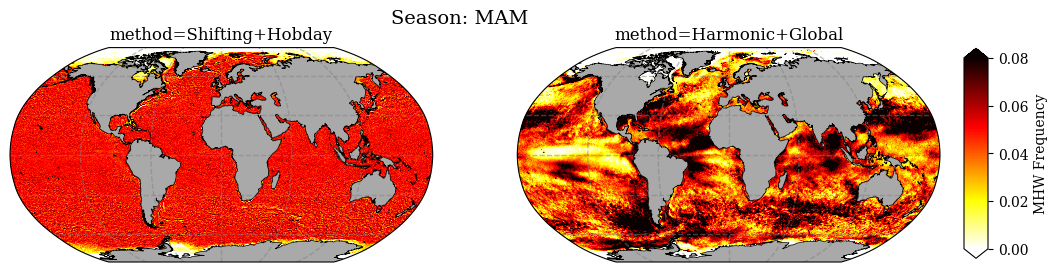

2026-10-18 22:41:00 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:41:06 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 6.03s


2026-10-18 22:41:06 - marEx.plotX.gridded - INFO - [PID:2273093] - Starting Gridded plot rendering


2026-10-18 22:41:12 - marEx.plotX.gridded - INFO - [PID:2273093] - Completed Gridded plot rendering in 6.08s


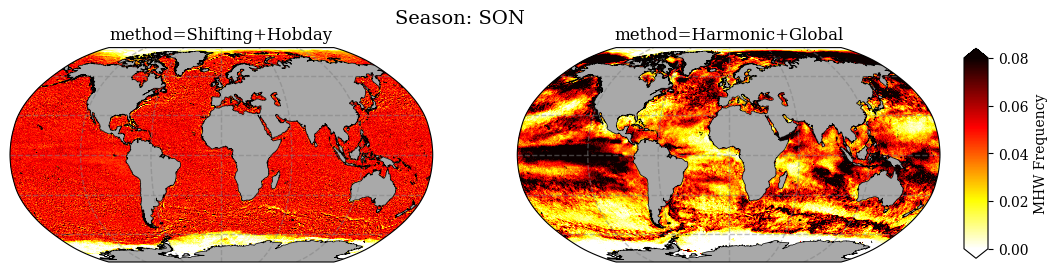

In [14]:
seasonal_frequency = by_method(lambda ds: ds.extreme_events.groupby("time.season").mean(dim="time")).persist()

config = marEx.PlotConfig(
    var_units="MHW Frequency",
    cmap="hot_r",
    clim=[0, 0.08],
    grid_labels=False,
    show_colorbar=True,
)
plot_by_season(seasonal_frequency, config)

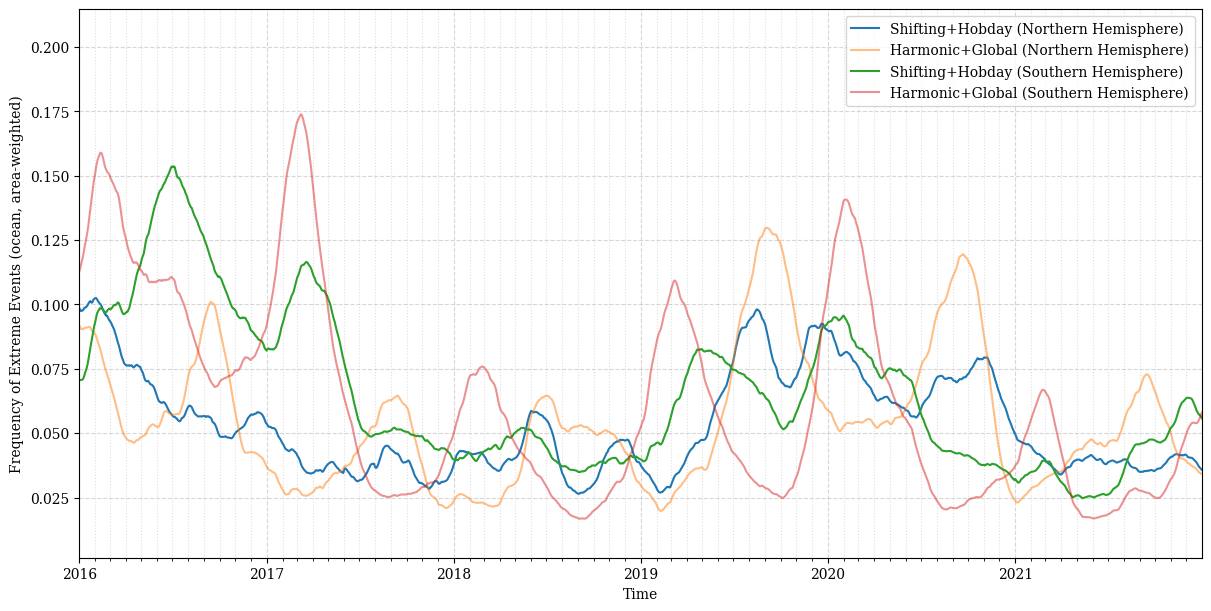

In [15]:
hemispheres = {"Northern Hemisphere": slice(0, 90), "Southern Hemisphere": slice(-90, 0)}


def plot_hemispheres(ax, reduce):
    """Hemisphere-mean event frequency (ocean cells only, cos(latitude)-weighted) for both methods, passed through `reduce`, on `ax`."""
    for hemisphere, lats in hemispheres.items():
        for (name, ds), alpha in zip(methods.items(), [1.0, 0.5]):
            ocean_events = ds.extreme_events.where(ds.mask).sel(lat=lats)
            weights = np.cos(np.deg2rad(ocean_events.lat))
            series = reduce(ocean_events.weighted(weights).mean(dim=["lat", "lon"]))
            ax.plot(series[series.dims[0]], series, label=f"{name} ({hemisphere})", alpha=alpha)
    ax.set_ylabel("Frequency of Extreme Events (ocean, area-weighted)")
    ax.grid(True, which="major", linestyle="--", alpha=0.5)
    ax.legend()


# 60-day running mean
fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
plot_hemispheres(ax, lambda series: series.rolling(time=60).mean())
ax.grid(True, which="minor", linestyle=":", alpha=0.4, axis="x")
ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(2, 13)))
ax.set_xlim(np.datetime64(plot_window.start), np.datetime64(plot_window.stop))
ax.set_xlabel("Time")
plt.show()

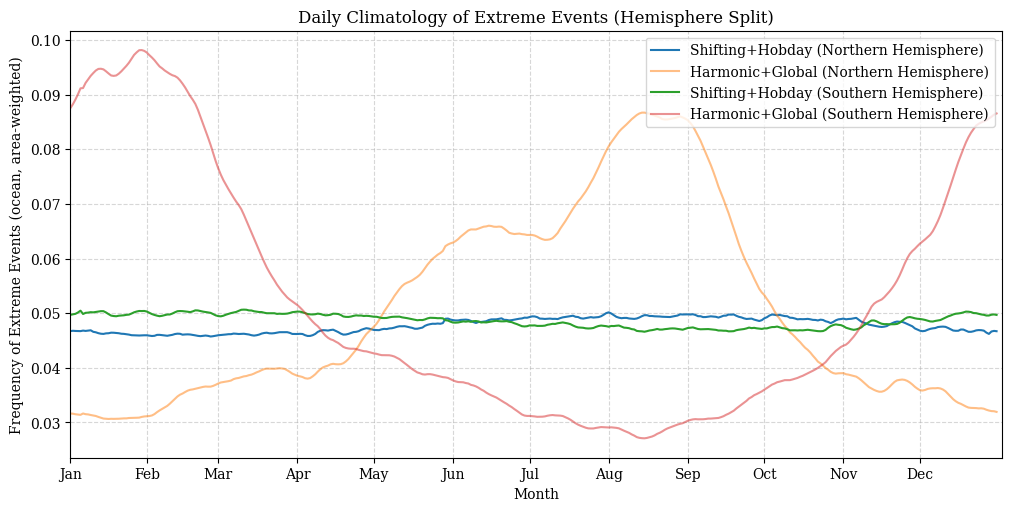

In [16]:
def daily_climatology(series):
    return series.rolling(time=10, center=True).mean().groupby("time.dayofyear").mean(dim="time").isel(dayofyear=slice(0, -2))


month_starts = [1] + list(np.cumsum([calendar.monthrange(2001, m)[1] for m in range(1, 12)]))
month_labels = [calendar.month_abbr[m] for m in range(1, 13)]

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
plot_hemispheres(ax, daily_climatology)
ax.set_xticks(month_starts, month_labels)
ax.set_xlim(1, 366)
ax.set_xlabel("Month")
ax.set_title("Daily Climatology of Extreme Events (Hemisphere Split)")
plt.show()

## Wall Time and Memory

Peak memory summed over workers, the largest single worker, and the client (this kernel), per stage.

In [17]:
monitor.summary()

,wall (min),peak worker memory (GB),peak per worker (GB),peak client memory (GB),peak spilled to disk (GB),worker restarts
stage,,,,,,
Detect: shifting baseline + Hobday,3.52,1110.76,5.25,2.21,46.57,0
Detect: harmonic detrend + global threshold,0.79,440.18,2.82,2.37,0.00,0
total,4.30,1110.76,5.25,2.37,46.57,0


In [18]:
client.close()